# ME-446 Complex Engineering Problem
## ASHRAE Great Energy Predictor III — Reproducible Analysis

**Project:** AI-Based Building Energy Consumption Prediction and Analysis for HVAC and Energy Efficiency Applications  
**Course:** ME-446 AI & Internet of Things, Fall 2026  
**Department:** Mechanical Engineering, NED University of Engineering and Technology

This notebook runs the project pipeline from the original Kaggle files to the final model, evaluation tables, and dashboard extracts. It supports two scopes:

- `local_subset` — the documented 120-building subset used for the reported local results.
- `full` — all 1,413 electricity buildings, intended for Google Colab or a high-memory machine.

**Dataset approval is pending.** No teacher approval or dataset uniqueness is claimed. **Tableau workbook:** only data and a build guide are supplied; no workbook has been published. **Full-data metrics:** not yet produced; do not present subset results as full-data results.

### Reproducibility controls

- Chronological split: train Jan–Sep 2016, validation Oct–Nov 2016, test Dec 2016.
- Test period is not used for model selection.
- Seed 42 for subset selection, sampling, fitting, and plots.
- Weather forward fill is past-only with a three-hour limit.
- All learned preprocessing is fitted inside training pipelines.
- Raw CSVs are retained unchanged.

### How to run

1. Place the project in Google Drive/Colab or run locally from the project root.
2. Add a Colab secret named `KAGGLE_API_TOKEN`, or place `kaggle.json` in `~/.kaggle/`.
3. Select the scope below and run all cells.
4. For a quick inspection of existing local artifacts without retraining, set `ME446_REUSE=1`.

The local machine used for the reported results has 4 CPU cores and 3.6 GB RAM, so local training uses the subset. Full mode is intended for a high-RAM Colab runtime.

In [1]:
import os
import sys
import json
import platform
import subprocess
import pandas as pd
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
candidates = [
    Path.cwd(),
    Path("/content/ashrae-energy-cep"),
    Path("/content/AI IOT CEP"),
    Path.home() / "Desktop" / "AI IOT CEP",
]
PROJECT_ROOT = next(
    (path.resolve() for path in candidates if (path / "src" / "config.py").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project. Upload the project folder or update PROJECT_ROOT."
    )
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_MODE = os.getenv("ME446_DATA_MODE", "local_subset").strip().lower()
assert DATA_MODE in {"local_subset", "full"}, "ME446_DATA_MODE must be local_subset or full"
REUSE = os.getenv("ME446_REUSE", "0") == "1"
RUN_EXTENSIONS = os.getenv(
    "ME446_RUN_EXTENSIONS", "1" if DATA_MODE == "local_subset" else "0"
) == "1"
RUN_EDA = os.getenv(
    "ME446_RUN_EDA", "1" if DATA_MODE == "local_subset" else "0"
) == "1"

if DATA_MODE == "full":
    os.environ["ME446_SCOPE"] = "full"
    os.environ.setdefault("ME446_RF_SAMPLE_ROWS", "500000")
    os.environ.setdefault("ME446_LINEAR_SAMPLE_ROWS", "2000000")
else:
    os.environ["ME446_SCOPE"] = "local_subset"
    os.environ.setdefault("ME446_RF_SAMPLE_ROWS", "250000")

print("Project root:", PROJECT_ROOT)
print("Colab:", IN_COLAB)
print("Scope:", DATA_MODE)
print("Reuse existing artifacts:", REUSE)
print("Run EDA:", RUN_EDA)
print("Run extensions (generalization + unseen cases):", RUN_EXTENSIONS)
print("Python:", platform.python_version())
print("RF sample rows:", os.environ["ME446_RF_SAMPLE_ROWS"])
print("Linear sample rows:", os.environ.get("ME446_LINEAR_SAMPLE_ROWS", "all"))

Project root: /home/shahbaz/Desktop/AI IOT CEP
Colab: False
Scope: local_subset
Reuse existing artifacts: True
Run EDA: True
Run extensions (generalization + unseen cases): True
Python: 3.12.3
RF sample rows: 250000
Linear sample rows: all


In [2]:
if IN_COLAB:
    packages = [
        "kagglehub>=1.0",
        "duckdb>=1.0",
        "pyarrow>=15",
        "plotly>=5",
        "tabulate>=0.9",
        "streamlit>=1.40",
    ]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)
    print("Colab dependencies installed.")
else:
    print("Local environment: install requirements.txt before running.")

Local environment: install requirements.txt before running.


## 1. Dataset acquisition and typed storage

The raw files are read directly from `data/raw/`. They are never overwritten. Large CSV scans are avoided by converting to typed Parquet in `data/interim/`.

In [3]:
if IN_COLAB:
    try:
        from google.colab import userdata
        token = userdata.get("KAGGLE_API_TOKEN")
        if token:
            os.environ["KAGGLE_API_TOKEN"] = token
            print("Kaggle API token loaded from Colab secrets.")
    except Exception as exc:
        print("Could not load the Colab secret:", type(exc).__name__)
        print("Add KAGGLE_API_TOKEN in Colab Secrets, or upload kaggle.json to ~/.kaggle/.")
else:
    print("Local run: using existing data/raw files or KAGGLE_API_TOKEN / ~/.kaggle/kaggle.json.")

Local run: using existing data/raw files or KAGGLE_API_TOKEN / ~/.kaggle/kaggle.json.


In [4]:
from src.data_loading import REQUIRED_RAW_FILES, verify_raw_files

missing = [path for path in REQUIRED_RAW_FILES if not path.exists()]
if missing:
    import shutil
    import kagglehub

    print("Downloading ASHRAE Great Energy Predictor III from Kaggle...")
    cache = Path(kagglehub.dataset_download(
        "sumit261124/ashrae-great-energy-predictor-iii-dataset"
    ))
    for destination in REQUIRED_RAW_FILES:
        matches = list(cache.rglob(destination.name))
        if not matches:
            raise FileNotFoundError(f"{destination.name} was not found in the Kaggle download.")
        shutil.copy2(matches[0], destination)
        print("Copied", destination.name)
else:
    print("All required raw files are already present.")

verify_raw_files()
print("Raw files verified.")

All required raw files are already present.
Raw files verified.


In [5]:
from src.data_loading import convert_raw_to_parquet

if not REUSE:
    convert_raw_to_parquet()
    print("Typed Parquet files written to data/interim/.")
else:
    print("Reuse mode: skipped Parquet conversion.")

Reuse mode: skipped Parquet conversion.


## 2. Data-quality audit

The audit computes row counts, duplicate business keys, meter composition, metadata missingness, weather coverage, and site/train overlap directly from the data.

In [6]:
if not REUSE:
    from src.inspect_data import main as run_audit
    run_audit()

inventory_path = PROJECT_ROOT / "reports" / "data_inventory.md"
if not inventory_path.exists():
    raise FileNotFoundError("Run the audit cell to create reports/data_inventory.md.")
print(inventory_path.read_text(encoding="utf-8")[:6000])

# ASHRAE Great Energy Predictor III — Data Inventory

Generated by `src/inspect_data.py` from the raw files in `data/raw/`. All row counts were computed with DuckDB directly from the CSV/Parquet files.

## Key findings

- Training observations: **20,216,100** across **1449** buildings.
- Training period: **2016-01-01 00:00:00** to **2016-12-31 23:00:00** (one calendar year, leap year 2016).
- Test features period: **2017-01-01 00:00:00** to **2018-12-31 23:00:00**; test labels are not provided.
- Electricity (meter 0): **12,060,910** rows across **1413** buildings, **4.40%** zero readings.
- Duplicate (building, meter, timestamp) keys in train: **0**.
- Meter coding observed: 0 = electricity, 1 = chilled water, 2 = steam, 3 = hot water, consistent with the competition documentation.

## Interpretation notes

- `meter_reading` units are not explicitly stated in the downloadable CSV. The competition documentation defines the target as energy consumed in kWh; the re-uploaded file does not

## 3. Preprocessing, feature engineering, and chronological split

Missing metadata is retained rather than imputed with invented values. Weather is forward-filled only from the past, with a three-hour limit. `cloud_coverage`, precipitation, and pressure retain explicit missingness flags. The target is electricity (`meter == 0`).

In [7]:
from src import config
from src.preprocessing import build_model_dataset, save_subset, select_subset_buildings

summary_path = config.DATA_PROCESSED / "dataset_summary.json"
if not REUSE:
    if DATA_MODE == "full":
        result = build_model_dataset(None)
    else:
        subset = select_subset_buildings()
        save_subset(subset)
        result = build_model_dataset(subset["building_id"].tolist())
else:
    if not summary_path.exists():
        raise FileNotFoundError("No existing dataset summary. Set ME446_REUSE=0 to build it.")
    result = json.loads(summary_path.read_text(encoding="utf-8"))

summary = pd.DataFrame(result["splits"])
display(summary)
splits = set(summary["split"])
assert {"train", "validation", "test"}.issubset(splits), "All three chronological splits are required."
assert summary["n_rows"].sum() == result["total_rows"]
print("Total rows:", f"{result['total_rows']:,}")
print("Scope:", result["scope"])
print("Dataset:", config.MODEL_DATASET_PARQUET)
print("Split order check:")
for split in ("train", "validation", "test"):
    row = summary[summary["split"] == split].iloc[0]
    print(f"  {split:10s} {row['first_timestamp']} -> {row['last_timestamp']}")

,split,n_rows,n_buildings,first_timestamp,last_timestamp,mean_reading,zero_readings
0,test,87308,120,2016-12-01 00:00:00,2016-12-31 23:00:00,196.003962,126
1,train,769122,120,2016-01-01 00:00:00,2016-09-30 23:00:00,186.764533,44796
2,validation,174537,120,2016-10-01 00:00:00,2016-11-30 23:00:00,194.068485,662


Total rows: 1,030,967
Scope: local_subset
Dataset: /home/shahbaz/Desktop/AI IOT CEP/data/processed/model_dataset.parquet
Split order check:
  train      2016-01-01 00:00:00 -> 2016-09-30 23:00:00
  validation 2016-10-01 00:00:00 -> 2016-11-30 23:00:00


  test       2016-12-01 00:00:00 -> 2016-12-31 23:00:00


## 4. Exploratory data analysis

The EDA quantifies the skewed demand distribution, daily/weekly cycles, site-specific temperature response, primary-use differences, and the building-size relationship. Five engineering insights are documented in `reports/engineering_insights.md`.

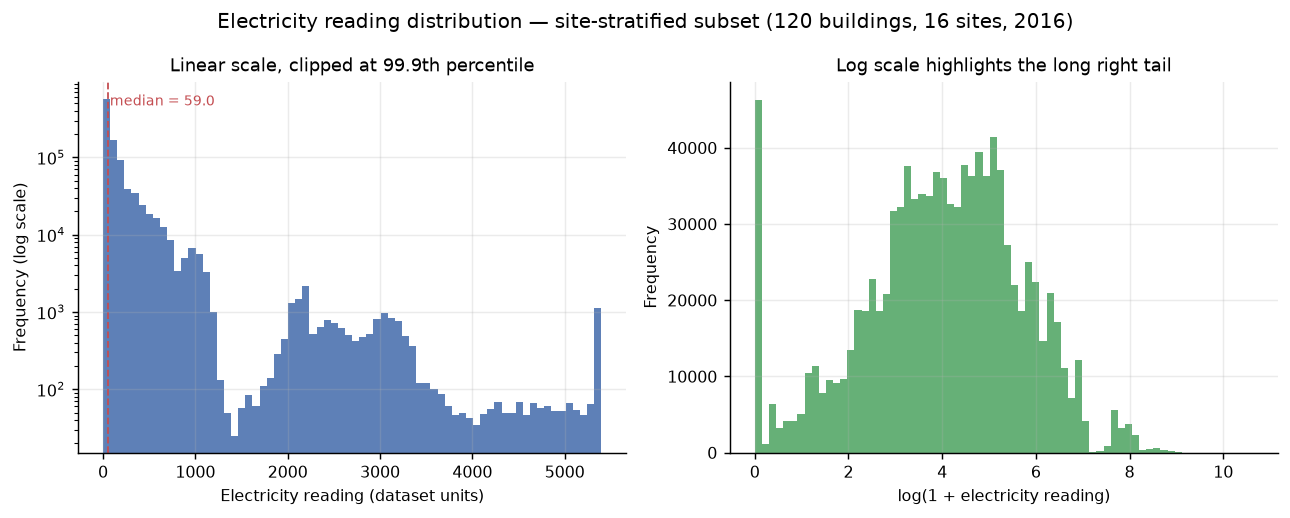

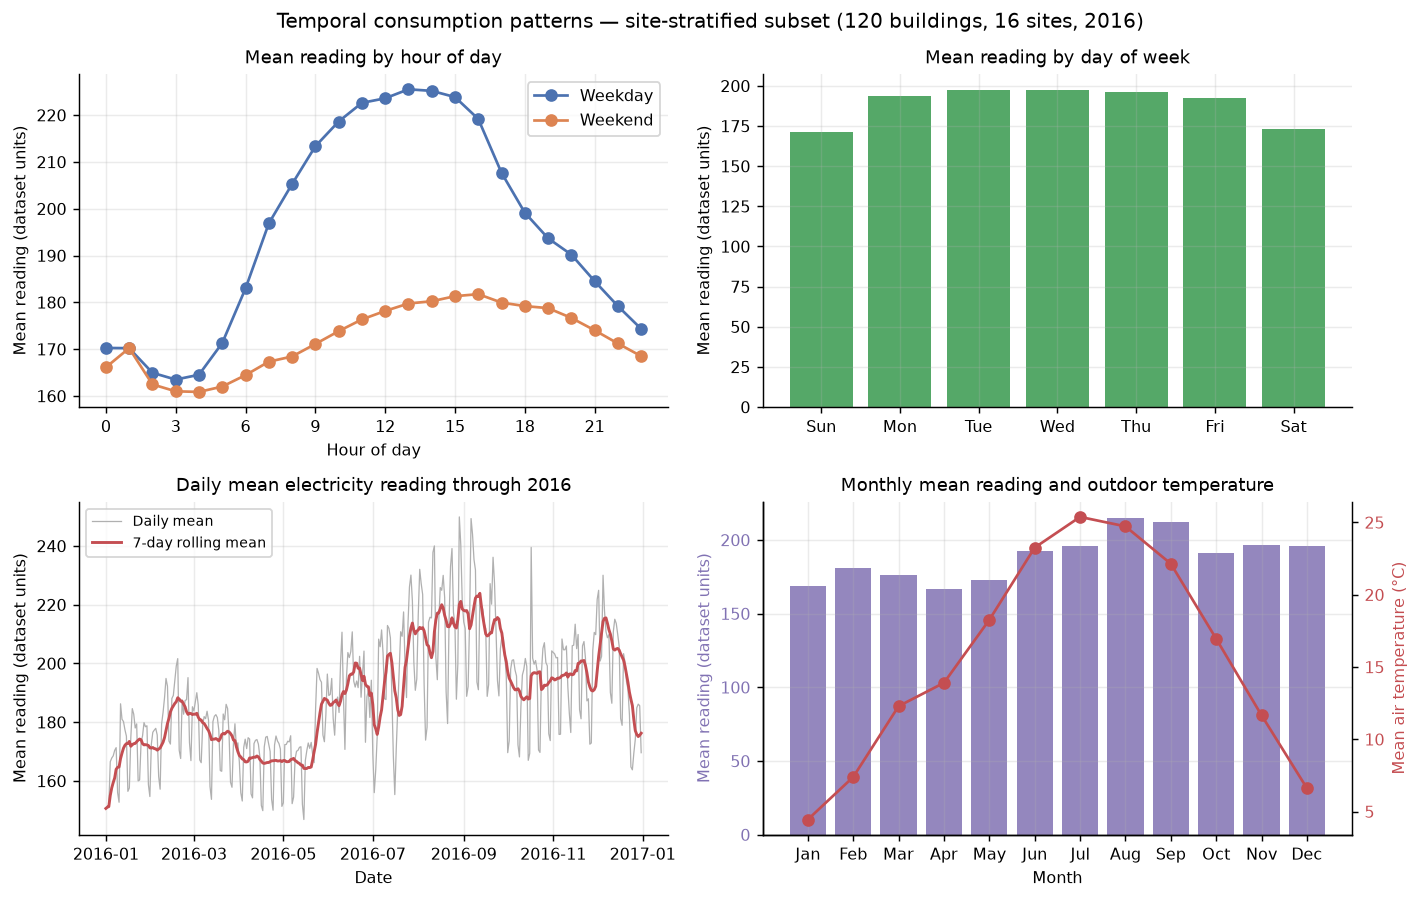

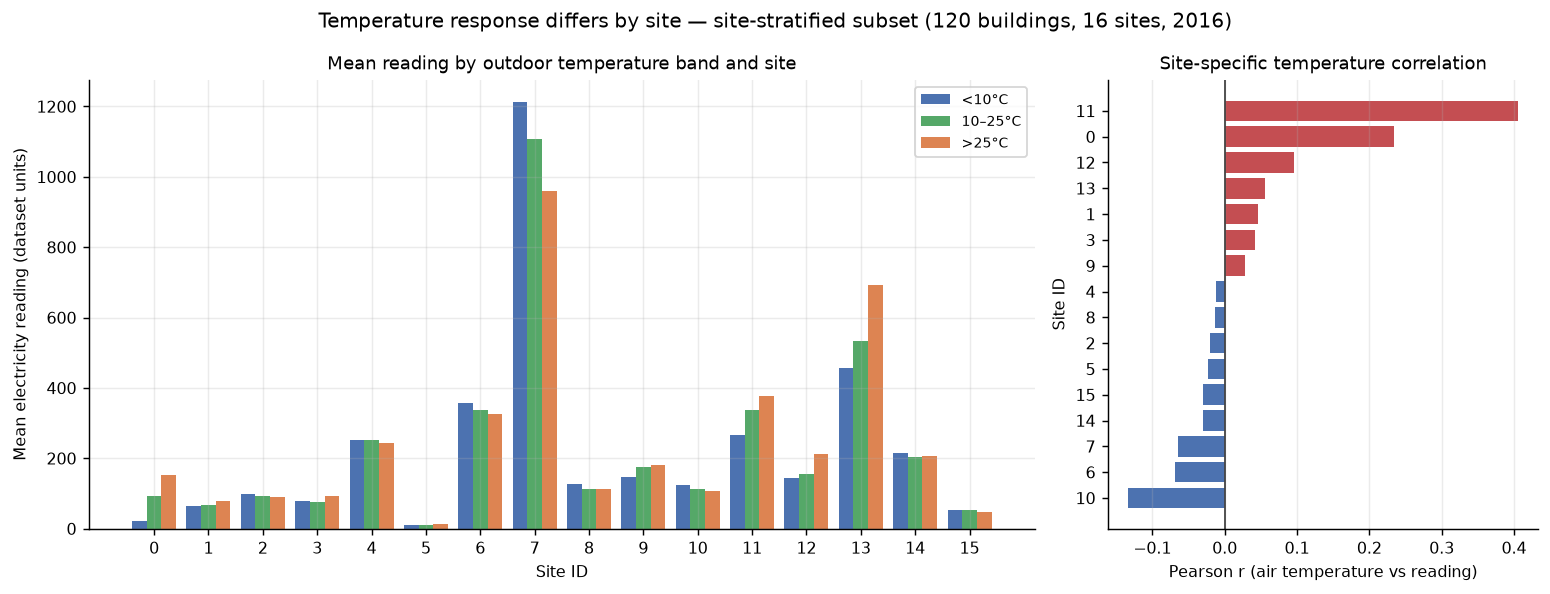

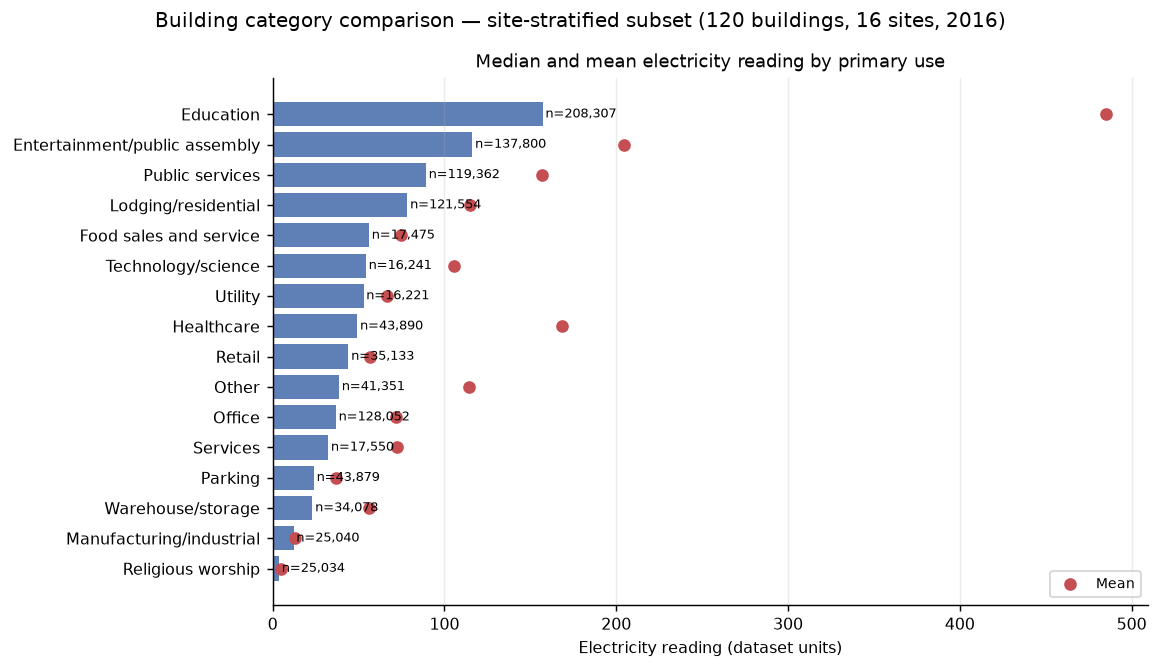

In [8]:
if RUN_EDA and not REUSE:
    from src.eda import main as run_eda
    run_eda()
elif not RUN_EDA:
    print("EDA is skipped in full mode by default to control memory. Set ME446_RUN_EDA=1 to enable it.")

from IPython.display import Image, display

if RUN_EDA:
    for figure_name in [
        "reading_distribution.png",
        "temporal_patterns.png",
        "temperature_response_by_site.png",
        "primary_use_consumption.png",
    ]:
        figure_path = config.FIGURES_DIR / figure_name
        if figure_path.exists():
            display(Image(filename=str(figure_path), width=780))
        else:
            print("Missing figure:", figure_path)

## 5. Model training and comparison

The three required regressors are Linear Regression, Random Forest, and HistGradientBoosting, plus a mean baseline. The selection rule is **lowest validation RMSE**. The December test period is evaluated only after selection.

Local subset settings: Random Forest uses a seeded 250,000-row sample; Linear Regression and HistGradientBoosting use all 769,122 training rows. Full mode: HGB uses all training rows, Linear Regression uses 2,000,000 sampled rows, and Random Forest uses 500,000 sampled rows.

In [9]:
if not REUSE:
    from src.train_models import main as run_training
    run_training()
else:
    print("Reuse mode: using the saved model and comparison table.")

metadata = json.loads((config.MODELS_DIR / config.METADATA_FILENAME).read_text(encoding="utf-8"))
comparison = pd.read_csv(config.TABLES_DIR / "model_comparison.csv")
display(comparison)
print("Selected model:", metadata["model_name"])
print("Selection rule:", metadata["selection_rule"])
print("Scope:", metadata["scope"])
print("Best validation RMSE:", round(metadata["best_validation_rmse"], 3))
print("Test metrics:", {key: round(value, 4) for key, value in metadata["test_metrics"].items()})

Reuse mode: using the saved model and comparison table.


,model,split,n_rows,mae,rmse,r2,rmsle,fit_seconds,predict_seconds
0,Mean baseline,validation,174537,205.211972,411.665340,-0.000315,1.921723,0.59,0.020
1,Mean baseline,test,87308,209.565800,406.049758,-0.000518,1.919525,0.59,0.020
2,Linear Regression,validation,174537,68.401936,223.031495,0.706383,0.981124,53.39,4.350
3,Linear Regression,test,87308,61.386520,154.513150,0.855124,0.941511,53.39,4.350
4,Random Forest,validation,174537,29.353929,166.922466,0.835533,0.425584,232.40,5.941
5,Random Forest,test,87308,32.053883,78.903609,0.962220,0.447625,232.40,5.941
6,HistGradientBoosting,validation,174537,32.657015,165.735393,0.837864,0.578224,53.91,7.316
7,HistGradientBoosting,test,87308,33.197261,69.776581,0.970455,0.590658,53.91,7.316


Selected model: HistGradientBoosting
Selection rule: Lowest validation RMSE; test period held out until after selection.
Scope: local_subset
Best validation RMSE: 165.735
Test metrics: {'n_rows': 87308.0, 'mae': 33.1973, 'rmse': 69.7766, 'r2': 0.9705, 'rmsle': 0.5907, 'fit_seconds': 53.91, 'predict_seconds': 7.316}


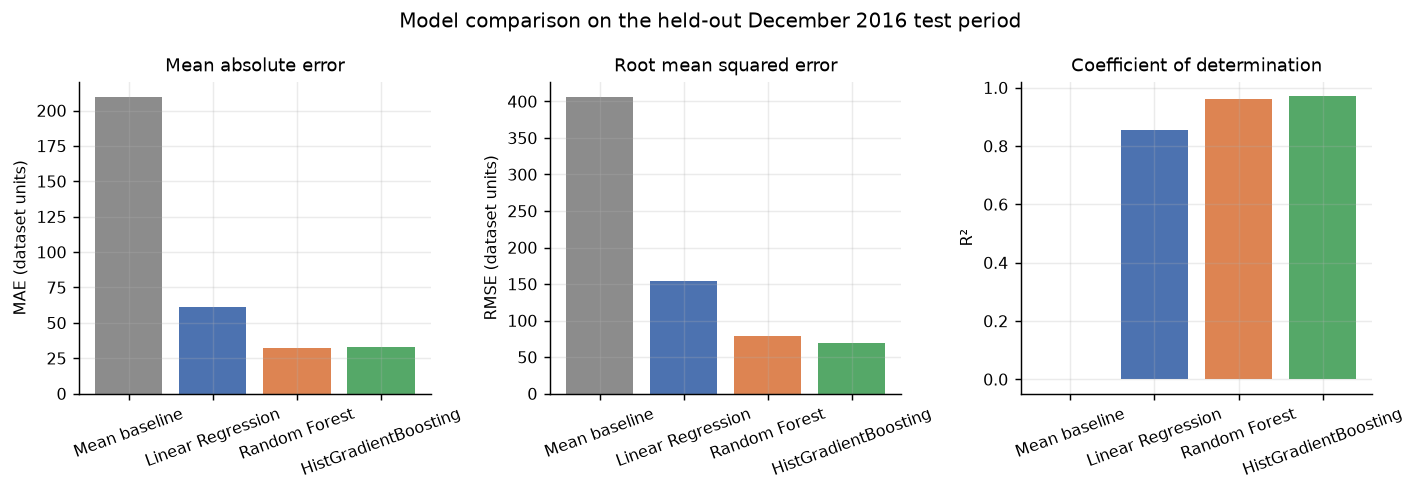

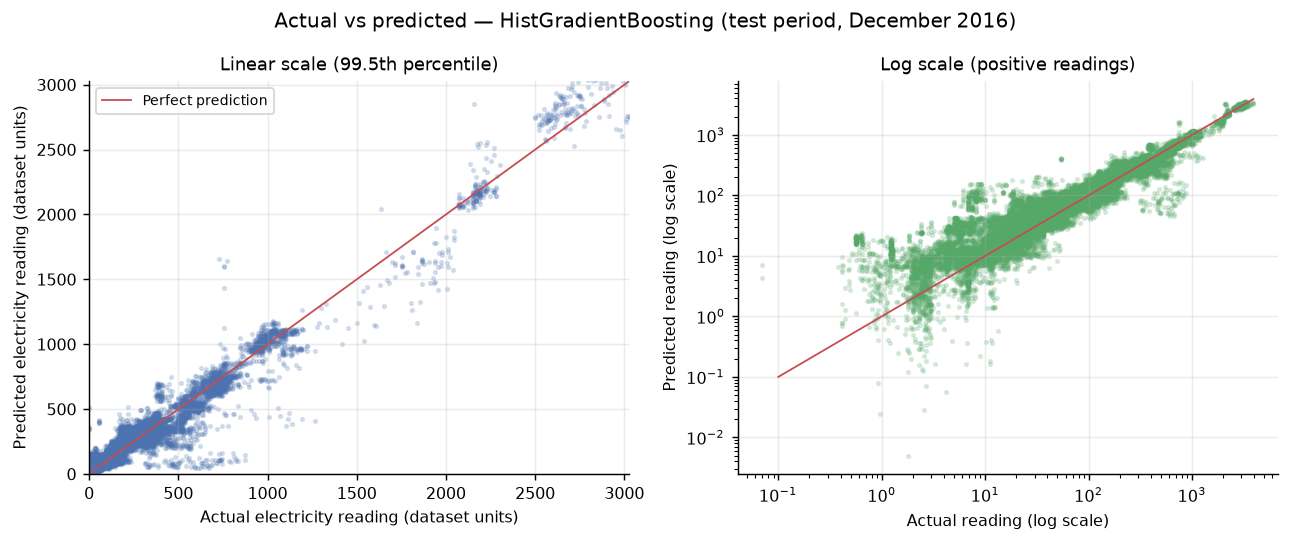

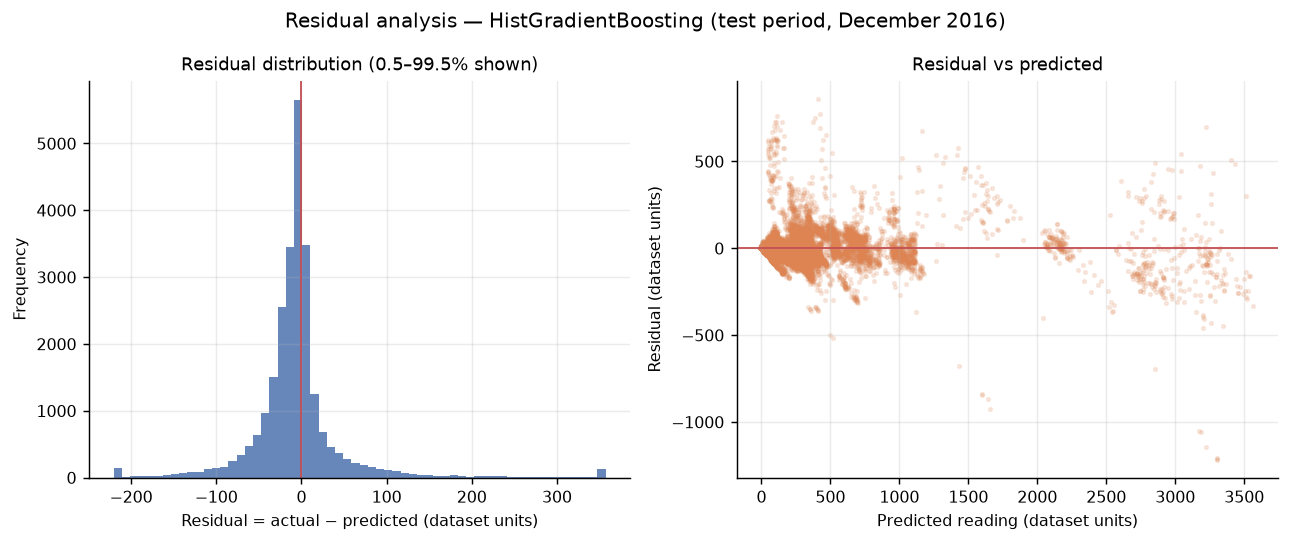

In [10]:
for figure_name in ["model_comparison.png", "actual_vs_predicted.png", "residual_analysis.png"]:
    figure_path = config.FIGURES_DIR / figure_name
    if figure_path.exists():
        display(Image(filename=str(figure_path), width=900))
    else:
        print("Missing figure:", figure_path)

## 6. Error analysis, generalization, and unseen cases

The main model uses `building_id`, so strong test performance applies to buildings observed during training. The building-holdout experiment removes 20% of buildings entirely and exposes the model's poor transfer to new buildings. Two unseen held-out rows are also demonstrated through the reusable inference interface.

,building_group,mae,rmse,r2,rmsle,n_rows,actual_mean,predicted_mean
0,unseen_buildings_test,150.507233,321.332658,-0.554764,1.525288,18937,176.990956,242.485253
1,seen_buildings_test,33.864518,74.148385,0.971351,0.595271,68371,201.270073,204.984196
2,seen_buildings_validation,33.025445,183.875291,0.830503,0.576127,136713,200.122211,203.773099


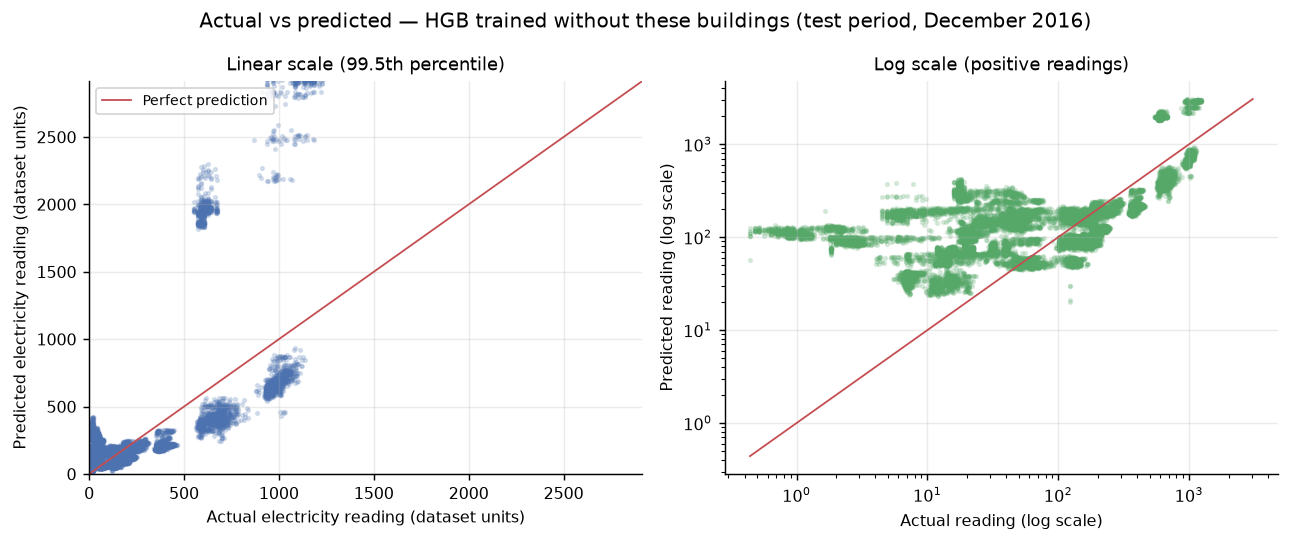

,case_id,building_id,timestamp,site_id,primary_use,square_feet,air_temperature_c,actual_reading,predicted_reading,absolute_error,percentage_error
0,case_1_high_demand,1088,2016-12-19 15:00:00,13,Education,287594.0,-10.6,3427.60,3417.325315,10.274685,0.299763
1,case_2_typical_demand,386,2016-12-09 06:00:00,3,Entertainment/public assembly,17262.0,0.6,41.16,41.160360,0.000360,0.000874


In [11]:
if RUN_EXTENSIONS and not REUSE:
    from src.generalization import main as run_generalization
    run_generalization()

if RUN_EXTENSIONS:
    generalization_path = config.TABLES_DIR / "generalization_building_holdout.csv"
    if generalization_path.exists():
        display(pd.read_csv(generalization_path))
        display(Image(
            filename=str(config.FIGURES_DIR / "unseen_buildings_actual_vs_predicted.png"),
            width=850,
        ))
    else:
        print("Run the generalization cell to create the table.")
else:
    print("Generalization experiment skipped in this configuration.")

if RUN_EXTENSIONS and not REUSE:
    from src.predict import main as run_predictions
    run_predictions()

if RUN_EXTENSIONS:
    cases_path = config.TABLES_DIR / "unseen_case_predictions.csv"
    if cases_path.exists():
        display(pd.read_csv(cases_path))
    else:
        print("Run the prediction cell to create the unseen-case table.")
else:
    print("Unseen-case demonstration skipped in this configuration.")

## 7. Dashboard-ready outputs

The Tableau extracts and the supplementary Streamlit app are generated from the processed data and saved predictions. The Streamlit app does not replace the required Tableau Public dashboard.

Run locally:

```bash
streamlit run dashboard/streamlit_app.py
```

Tableau data dictionary: `data/dashboard/README.md`  
Tableau specification: `dashboard/dashboard_specification.md`  
Tableau build guide: `dashboard/tableau_build_guide.md`

In [12]:
if DATA_MODE == "local_subset":
    if not REUSE:
        from src.build_dashboard_data import main as build_dashboard
        build_dashboard()
    else:
        print("Reuse mode: existing dashboard extracts retained.")
else:
    print("Full mode: dashboard exports are intentionally not generated here.")

for path in [
    config.DATA_DASHBOARD / "tableau_data" / "electricity_hourly.csv",
    config.DATA_DASHBOARD / "tableau_data" / "model_comparison.csv",
    config.DATA_DASHBOARD / "tableau_data" / "model_test_predictions.csv",
]:
    if path.exists():
        print(f"{path.name:35s} {path.stat().st_size / 1e6:8.2f} MB")
    else:
        print("Missing:", path)

Reuse mode: existing dashboard extracts retained.
electricity_hourly.csv                107.60 MB
model_comparison.csv                    0.00 MB
model_test_predictions.csv             42.27 MB


## 8. Final output manifest and limitations

The notebook does not claim a Tableau workbook, teacher approval, or full-data metrics. The local results are subset results.

In [13]:
manifest = [
    ("Data audit", config.REPORTS_DIR / "data_inventory.md"),
    ("Approval proposal", config.REPORTS_DIR / "dataset_approval_proposal.md"),
    ("Model dataset", config.MODEL_DATASET_PARQUET),
    ("Final model", config.MODELS_DIR / config.MODEL_FILENAME),
    ("Model metadata", config.MODELS_DIR / config.METADATA_FILENAME),
    ("Model comparison", config.TABLES_DIR / "model_comparison.csv"),
    ("Generalization table", config.TABLES_DIR / "generalization_building_holdout.csv"),
    ("Unseen cases", config.TABLES_DIR / "unseen_case_predictions.csv"),
    ("EDA summary", config.TABLES_DIR / "eda_summary.json"),
    ("Tableau data dictionary", config.DATA_DASHBOARD / "README.md"),
    ("Streamlit app", config.DASHBOARD_DIR / "streamlit_app.py"),
]
rows = []
for label, path in manifest:
    rows.append({
        "artifact": label,
        "exists": path.exists(),
        "size_mb": round(path.stat().st_size / 1e6, 3) if path.exists() else None,
        "path": str(path.relative_to(PROJECT_ROOT)),
    })
manifest_frame = pd.DataFrame(rows)
display(manifest_frame)
assert manifest_frame.loc[manifest_frame["artifact"].isin([
    "Model dataset", "Final model", "Model metadata", "Model comparison"
]), "exists"].all(), "Core modeling artifacts are missing."

print("Limitations:")
print("- Local results use 120 buildings, not all 1,413 electricity buildings.")
print("- The model relies on building_id; unseen-building R2 is strongly negative.")
print("- December has much lower zero-reading prevalence than the training period.")
print("- Weather is site-level and incomplete; metadata missingness is substantial.")
print("- Target units are documented as kWh but not independently verified.")
print("- Tableau workbook and full-data metrics are pending user action.")
print("Notebook completed.")

,artifact,exists,size_mb,path
0,Data audit,True,0.019,reports/data_inventory.md
1,Approval proposal,True,0.006,reports/dataset_approval_proposal.md
2,Model dataset,True,5.244,data/processed/model_dataset.parquet
3,Final model,True,0.743,models/final_model.joblib
4,Model metadata,True,0.002,models/model_metadata.json
5,Model comparison,True,0.001,reports/tables/model_comparison.csv
6,Generalization table,True,0.000,reports/tables/generalization_building_holdout...
7,Unseen cases,True,0.000,reports/tables/unseen_case_predictions.csv
8,EDA summary,True,0.015,reports/tables/eda_summary.json
9,Tableau data dictionary,True,0.004,data/dashboard/README.md


Limitations:
- Local results use 120 buildings, not all 1,413 electricity buildings.
- The model relies on building_id; unseen-building R2 is strongly negative.
- December has much lower zero-reading prevalence than the training period.
- Weather is site-level and incomplete; metadata missingness is substantial.
- Target units are documented as kWh but not independently verified.
- Tableau workbook and full-data metrics are pending user action.
Notebook completed.


## References

- ASHRAE. (2019). *Great Energy Predictor III*. Kaggle. https://www.kaggle.com/c/ashrae-energy-prediction
- Kaggle re-upload: https://www.kaggle.com/datasets/sumit261124/ashrae-great-energy-predictor-iii-dataset
- Miller, C., Arjunan, P., Kathirgamanathan, A., et al. (2020). The ASHRAE Great Energy Predictor III competition: Overview and results. *Science and Technology for the Built Environment*, 26(10), 1427–1447.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Tableau. *Tableau Public/Cloud documentation*. https://help.tableau.com/
- Streamlit. *Streamlit documentation*. https://docs.streamlit.io/